# Antiplane shear at the tip of a crack: perfect plasticity by alternate minimization

Companion notebook to *Variational Methods in Computational Mechanics* (S. Vidoli),
Chapter 8, Section "Perfect Plasticity", Example "Antiplane Shear at the Tip of a Crack".

In antiplane shear the displacement is $u(x, y)\,\mathbf{e}_z$, the plastic strain is described by a vector
$\boldsymbol\gamma$, and one step of the incremental problem of the book, starting from $\boldsymbol\gamma = \mathbf 0$, is
$$\min_{u,\ \boldsymbol\gamma}\ \int_\Omega \Big(\frac{\mu}{2}\,|\nabla u - \boldsymbol\gamma|^2 + \tau_c\,|\boldsymbol\gamma|\Big)\,dx ,$$
with the shear stress $\boldsymbol\tau = \mu(\nabla u - \boldsymbol\gamma)$ and the yield criterion $|\boldsymbol\tau| \le \tau_c$.

The domain is the upper half of a disk of radius $R_\infty$ centred at the tip of a crack that runs along the
negative $x$-axis. By symmetry $u = 0$ on the ligament ahead of the tip, while the crack lip is free.
On the outer circle we impose the exact solution of Hult and McClintock (1957): the plastic zone is a disk of radius
$R$ that passes through the tip and lies ahead of it; outside it the field is the elastic crack-tip field of a crack
whose tip is shifted by $R$; inside it $u = (2\tau_c R/\mu)\sin\vartheta$, with $\vartheta$ the polar angle at the tip.

**How to use it.** Run the cells in order (*Runtime → Run all* in Colab). Then change the parameters in the next
cell and run everything again.

In [1]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt

# ---------------------------------------------------------------- PARAMETERS
mu, tau_c = 1.0, 1.0     # shear modulus and yield stress in shear
R         = 1.0          # radius of the exact plastic zone (it fixes the load)
R_inf     = 10.0         # radius of the computational half disk, centred at the tip
n_r, n_t  = 60, 72       # rings and angular sectors of the polar mesh
grade     = 2.0          # rings at radii R_inf * (j/n_r)**grade: denser near the tip
max_it    = 1000         # iterations of the alternate minimization
# ---------------------------------------------------------------------------

## 1. Mesh and exact solution

A polar mesh centred at the tip $P = (0, 0)$: rays at the angles $\vartheta_i = \pi i/n_t$, rings graded towards the
tip. Inside the plastic zone the exact $u$ depends on $\vartheta$ only, and the rays of the mesh follow it.
The centre of the exact plastic disk is $O = (R, 0)$.

In [2]:
def make_mesh():
    th = np.linspace(0, np.pi, n_t + 1)
    rho = R_inf * (np.arange(1, n_r + 1) / n_r)**grade
    X = [(0.0, 0.0)]
    idx = np.zeros((n_r + 1, n_t + 1), int)              # idx[j, i]: ring j, ray i (ring 0 = the tip)
    for j, r in enumerate(rho, start=1):
        for i, t in enumerate(th):
            idx[j, i] = len(X); X.append((r * np.cos(t), r * np.sin(t)))
    T = [(0, idx[1, i], idx[1, i + 1]) for i in range(n_t)]
    for j in range(1, n_r):
        for i in range(n_t):
            a, b, c, d = idx[j, i], idx[j + 1, i], idx[j + 1, i + 1], idx[j, i + 1]
            T += [(a, b, c), (a, c, d)]
    return np.array(X), np.array(T), idx, th

def u_exact(X):
    x, y = X[:, 0] - R, X[:, 1]                          # coordinates from the centre O of the plastic disk
    r, theta = np.hypot(x, y), np.arctan2(y, x)
    rho, vth = np.hypot(X[:, 0], X[:, 1]), np.arctan2(X[:, 1], X[:, 0])
    elastic = 2 * tau_c / mu * np.sqrt(R * r) * np.sin(theta / 2)
    plastic = 2 * tau_c / mu * R * np.sin(vth)
    return np.where(r >= R, elastic, plastic)

X, T, idx, th = make_mesh()
print(f"{len(X)} nodes, {len(T)} triangles")

4381 nodes, 8568 triangles


## 2. The solver: the code of the potential flow, plus a projection

- *Stiffness matrix*: linear triangles, assembled exactly as for the potential flow of Section 8.1; it does not
  change during the iterations, and it is factorized once (`splu`).
- *Essential conditions*: $u = 0$ on the ligament ($\vartheta = 0$), $u = u_{\rm exact}$ on the outer circle; the crack
  lip ($\vartheta = \pi$) is free.
- *Alternate minimization*: at fixed $\boldsymbol\gamma$ (constant on each element) the displacement solves
  $\mathbf K\mathbf U = \mathbf f_p$, with the nodal forces $\int\mu\,\boldsymbol\gamma\cdot\nabla\varphi_i$;
  at fixed $u$ the trial stress $\mu\nabla u_h$ of each element is projected on the disk $|\boldsymbol\tau| \le \tau_c$,
  and $\boldsymbol\gamma = \nabla u_h - \boldsymbol\tau/\mu$.

In [3]:
Gref = np.array([[-1., 1., 0.], [-1., 0., 1.]])
G = np.zeros((len(T), 2, 3)); A = np.zeros(len(T))
for e, tri in enumerate(T):
    Jac = (X[tri[1:]] - X[tri[0]]).T
    G[e] = np.linalg.solve(Jac.T, Gref); A[e] = 0.5 * abs(np.linalg.det(Jac))
I, J = np.repeat(T, 3, axis=1).ravel(), np.tile(T, 3).ravel()
K = mu * sp.csr_matrix(((A[:, None, None] * np.einsum('eai,eaj->eij', G, G)).ravel(), (I, J)), shape=(len(X),) * 2)

fixed = np.unique(np.r_[idx[:, 0], idx[n_r, :]])          # ligament (with the tip) and outer circle
ubar = np.zeros(len(X)); ubar[idx[n_r, :]] = u_exact(X[idx[n_r, :]])
free = np.setdiff1d(np.arange(len(X)), fixed)
lu = spla.splu(K[free][:, free].tocsc()); Kfc = K[free][:, fixed]

grad = lambda u: np.einsum('eai,ei->ea', G, u[T])
def project(g):                                            # stress on the disk |tau| <= tau_c, and gamma
    tr = mu * g; n = np.linalg.norm(tr, axis=1)
    tau = tr / np.maximum(1.0, n / tau_c)[:, None]
    return tau, g - tau / mu
def energy(u, gam):
    g = grad(u)
    return np.sum(A * (0.5 * mu * np.sum((g - gam)**2, axis=1) + tau_c * np.linalg.norm(gam, axis=1)))

u, gam, E = ubar.copy(), np.zeros((len(T), 2)), []
for m in range(max_it):
    f = np.bincount(T.ravel(), (mu * A[:, None] * np.einsum('ea,eai->ei', gam, G)).ravel(), len(X))
    u[free] = lu.solve(f[free] - Kfc @ ubar[fixed])
    tau, gam = project(grad(u))
    E.append(energy(u, gam))
E = np.array(E)
print(f"energy after {max_it} iterations: {E[-1]:.6f}")

energy after 1000 iterations: 16.458743


## 3. The plastic zone

Colours: $|\boldsymbol\tau_h|/\tau_c$ on each element; the plastic elements, where the stress is on the yield circle,
are white. The dashed circle is the exact plastic zone of radius $R$, through the tip.

plastic area 1.5365, exact 1.5708 (-2.2%); plastic zone ahead of the tip up to x = 2.023 R, exact 2 R


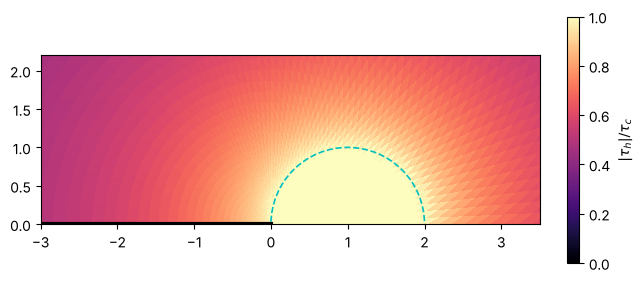

In [4]:
yielded = np.linalg.norm(gam, axis=1) > 1e-10
fig, ax = plt.subplots(figsize=(7, 3.2))
tp = ax.tripcolor(X[:, 0], X[:, 1], T, facecolors=np.linalg.norm(tau, axis=1) / tau_c, cmap="magma", vmin=0, vmax=1)
ax.add_patch(plt.Circle((R, 0), R, fill=False, ec="c", ls="--", lw=1.2))
ax.plot([-3 * R, 0], [0, 0], "k", lw=3)                    # the crack lip
ax.set_xlim(-3 * R, 3.5 * R); ax.set_ylim(0, 2.2 * R); ax.set_aspect("equal")
fig.colorbar(tp, ax=ax, label=r"$|\tau_h|/\tau_c$", fraction=0.03)
plt.show()

area_h = A[yielded].sum(); area = np.pi * R**2 / 2
ahead = X[T[yielded]][:, :, 0].max()
print(f"plastic area {area_h:.4f}, exact {area:.4f} ({100 * (area_h / area - 1):+.1f}%);"
      f" plastic zone ahead of the tip up to x = {ahead:.3f} R, exact 2 R")

## 4. Displacement and convergence

Left: the displacement on the circle $\rho = R/2$ around the tip, against the exact one. Inside the plastic zone
it is $(2\tau_c R/\mu)\sin\vartheta$, a field of the dislocation type: its gradient grows like $1/\rho$, so that
$u \notin H^1$, and yet the energy is finite.
Right: the energy of the iterates against the exact minimum, computed by quadrature from the exact solution. The
alternate minimization lowers the energy at every iteration, roughly like $1/m$ at first; after a few hundred
iterations what is left is the error of the mesh.

energy: computed 16.45874, exact 16.45403, relative error 2.9e-04
  after   10 iterations: relative error 5.2e-03
  after  100 iterations: relative error 8.8e-04
  after  300 iterations: relative error 4.7e-04
  after 1000 iterations: relative error 2.9e-04


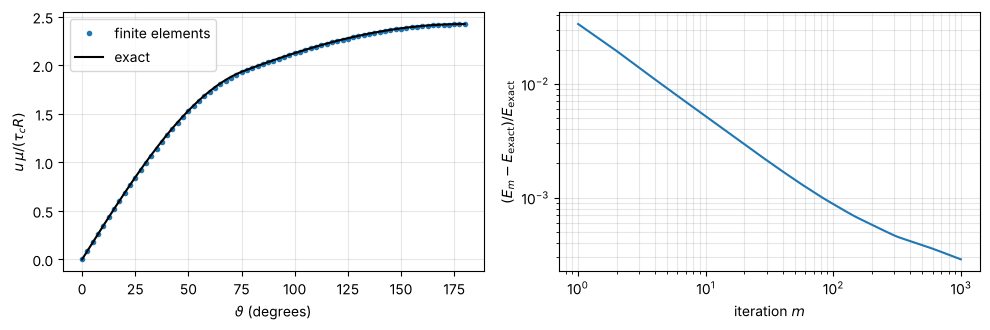

In [5]:
rho_q, ph_q = np.linspace(0, R_inf, 3001)[1:], np.linspace(0, np.pi, 3001)
P_, F_ = np.meshgrid(rho_q, ph_q, indexing="ij")
r_O = np.hypot(P_ * np.cos(F_) - R, P_ * np.sin(F_))       # distance from the centre of the plastic disk
dens = np.where(r_O >= R, tau_c**2 * R / (2 * mu * np.maximum(r_O, R)), 0.0)   # elastic energy density
E_exact = np.trapezoid(np.trapezoid(dens * P_, ph_q, axis=1), rho_q) + 3 * np.pi * tau_c**2 * R**2 / (4 * mu)

j = np.argmin(np.abs(R_inf * (np.arange(1, n_r + 1) / n_r)**grade - R / 2)) + 1
ring = idx[j, :]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
a1.plot(np.degrees(th), u[ring] * mu / (tau_c * R), "o", ms=3, label="finite elements")
tt = np.linspace(0, np.pi, 200)
a1.plot(np.degrees(tt), u_exact(np.c_[np.cos(tt), np.sin(tt)] * np.hypot(*X[ring[0]])) * mu / (tau_c * R), "k-", label="exact")
a1.set_xlabel(r"$\vartheta$ (degrees)"); a1.set_ylabel(r"$u\,\mu/(\tau_c R)$"); a1.legend(); a1.grid(alpha=0.3)
a2.loglog(np.arange(1, len(E) + 1), (E - E_exact) / E_exact, "-")
a2.set_xlabel("iteration $m$"); a2.set_ylabel(r"$(E_m - E_{\rm exact})/E_{\rm exact}$"); a2.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()
print(f"energy: computed {E[-1]:.5f}, exact {E_exact:.5f}, relative error {(E[-1] - E_exact) / E_exact:.1e}")
for m in (10, 100, 300, 1000):
    print(f"  after {m:4d} iterations: relative error {(E[m - 1] - E_exact) / E_exact:.1e}")

## Things to try
1. Change `R` (the load): the plastic zone grows as a disk through the tip, always tangent to the crack direction.
2. Coarsen the mesh (`n_r, n_t = 20, 24`): which features of the plastic zone survive?
3. Set `grade = 1.0`: the rings are no longer denser at the tip. How does the plastic area react?
4. Count the iterations needed to reach an energy error of $10^{-6}$ for `R = 0.5, 1, 2`: does the alternate
   minimization slow down as the plastic zone grows?
5. Replace `max(1, n/tau_c)` in `project` by `1`: no yield criterion, linear elasticity. What happens to the stress
   at the tip?